# 06 — Paderborn: Root-Causing the Invisible Bearings

Notebook 05 left four real bearings that no configuration could recognize —
KA15 (4 %), KA22 (7 %), KA30 (27 %), KI17 (35 %) — all failing toward
"Healthy", unrescued by better features *or* by mixing real bearings into
training. Before building anything on this benchmark (and before specifying
what the digital twin must simulate), we need to know **why**.

Ground truth from the benchmark's own paper (Lessmeier et al. 2016,
Table 5 — damage characterization of the accelerated-lifetime-test bearings)
turns this into two testable hypotheses:

1. **Damage mode.** KA15 and KA30 are the *only two* plastic-deformation
   (indentation) bearings in the set. Indentations are smooth dents pressed
   in by debris — not impulsive, crater-edged pits — so weak ball-pass
   excitation is physically expected.
2. **The KA22 anomaly.** KA22's Table-5 profile — *fatigue: pitting, OR,
   single damage, no repetition, extent 1, single point* — is **identical to
   KA04's**, yet KA04 transfers at 99 % and KA22 at 7 %. Metadata cannot
   explain that; the spectra must.

Plan: (i) join Table 5 with notebook 05's per-bearing transfer results;
(ii) look at the 20-run-averaged envelope spectra of the problem bearings
directly; (iii) run a **best-possible-detection** test — train on *all other
24 bearings including ten real ones* and see whether each problem bearing is
detectable by any training data at all. If a bearing fails even that, its
recordings are effectively **label noise** for vibration-based diagnosis at
this operating point.

*Side note for the related-work file: a 2025 evaluation-methodology paper
(arXiv 2509.22267) uses exactly this real-damage subset and independently
warns that recording-level splits leak bearing identity — the same
correction notebook 05 made. Our story is converging with the field's.*

In [1]:
import functools
import pathlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.io import loadmat
from scipy.signal import butter, sosfiltfilt, hilbert, get_window
from sklearn.ensemble import RandomForestClassifier

DATA_DIR = pathlib.Path("../data/raw/paderborn")
CONDITION = "N15_M07_F10"
FS_HIGH_HZ = 64_000
N_BALLS, BALL_D_MM, PITCH_D_MM = 8, 6.75, 29.05


def fault_freqs(fr):
    ratio = BALL_D_MM / PITCH_D_MM
    return N_BALLS / 2 * fr * (1 - ratio), N_BALLS / 2 * fr * (1 + ratio)


def load_channels(mat_path):
    mat_path = pathlib.Path(mat_path)
    struct = loadmat(mat_path)[mat_path.stem]
    channels = struct["Y"][0, 0][0]
    return {str(ch["Name"][0]): ch["Data"].squeeze() for ch in channels}


N_KEEP = 245_760  # 15 windows x 16384


@functools.lru_cache(maxsize=None)
def load_vib(code, run):
    chans = load_channels(DATA_DIR / code / f"{CONDITION}_{code}_{run}.mat")
    return chans["vibration_1"][:N_KEEP].astype(np.float32), chans["speed"].mean() / 60.0


SOS_ENV = butter(4, (1000, 20000), btype="bandpass", fs=FS_HIGH_HZ, output="sos")


def envelope(sig):
    env = np.abs(hilbert(sosfiltfilt(SOS_ENV, sig.astype(np.float64))))
    return env - env.mean()


WIN = 16_384
N_WIN = N_KEEP // WIN
HANN = get_window("hann", WIN)
WIN_FREQS = np.fft.rfftfreq(WIN, 1 / FS_HIGH_HZ)
FLOOR_MASK = (WIN_FREQS > 10) & (WIN_FREQS < 400)


def avg_env_spectrum(code, runs=range(1, 21)):
    """20-run-averaged windowed envelope power spectrum + mean shaft freq."""
    specs, frs = [], []
    for run in runs:
        vib, fr = load_vib(code, run)
        w = envelope(vib)[: N_WIN * WIN].reshape(N_WIN, WIN)
        w = w - w.mean(axis=1, keepdims=True)
        specs.append((np.abs(np.fft.rfft(w * HANN, axis=1)) ** 2).mean(axis=0))
        frs.append(fr)
    return np.mean(specs, axis=0), np.mean(frs)


# Lessmeier et al. 2016, Table 5 (real damage, accelerated lifetime test)
REAL_META = pd.DataFrame({
    "KA04": ("fatigue: pitting",              "OR", "S", "no repetition", 1, "single point"),
    "KA15": ("plastic deform.: indentations", "OR", "S", "no repetition", 1, "single point"),
    "KA16": ("fatigue: pitting",              "OR", "R", "random",        2, "single point"),
    "KA22": ("fatigue: pitting",              "OR", "S", "no repetition", 1, "single point"),
    "KA30": ("plastic deform.: indentations", "OR", "R", "random",        1, "distributed"),
    "KI04": ("fatigue: pitting",              "IR", "M", "no repetition", 1, "single point"),
    "KI14": ("fatigue: pitting",              "IR", "M", "no repetition", 1, "single point"),
    "KI16": ("fatigue: pitting",              "IR", "S", "no repetition", 3, "single point"),
    "KI17": ("fatigue: pitting",              "IR", "R", "random",        1, "single point"),
    "KI18": ("fatigue: pitting",              "IR", "S", "no repetition", 2, "single point"),
    "KI21": ("fatigue: pitting",              "IR", "S", "no repetition", 1, "single point"),
}, index=["Damage mode", "Element", "Comb.", "Arrangement", "Extent", "Characteristic"]).T

# chart tokens (validated light-mode reference palette)
C_BLUE, C_ORANGE = "#2a78d6", "#eb6834"
INK, INK2, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, BASE, SURFACE = "#e1e0d9", "#c3c2b7", "#fcfcfb"
plt.rcParams.update({
    "font.family": "sans-serif", "font.sans-serif": ["Segoe UI", "DejaVu Sans"],
    "text.color": INK, "axes.titlecolor": INK, "axes.labelcolor": INK2,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.edgecolor": BASE,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "legend.frameon": False,
})
print(REAL_META.to_string())

                        Damage mode Element Comb.    Arrangement Extent Characteristic
KA04               fatigue: pitting      OR     S  no repetition      1   single point
KA15  plastic deform.: indentations      OR     S  no repetition      1   single point
KA16               fatigue: pitting      OR     R         random      2   single point
KA22               fatigue: pitting      OR     S  no repetition      1   single point
KA30  plastic deform.: indentations      OR     R         random      1    distributed
KI04               fatigue: pitting      IR     M  no repetition      1   single point
KI14               fatigue: pitting      IR     M  no repetition      1   single point
KI16               fatigue: pitting      IR     S  no repetition      3   single point
KI17               fatigue: pitting      IR     R         random      1   single point
KI18               fatigue: pitting      IR     S  no repetition      2   single point
KI21               fatigue: pitting      IR

In [2]:
# Join Table 5 with notebook 05's transfer result (same model, same seed -> same numbers)
dataset = pd.read_csv("../data/processed/pu_N15_M07_F10_spectral_features_scaled.csv")
FEATURES_ALL = [c for c in dataset.columns if c not in ("Code", "Condition", "Domain", "Run")]
FUND = ["Env_BPFO_dB", "Env_BPFI_dB", "Env_fr_dB"]
RF_KW = dict(n_estimators=300, random_state=0, n_jobs=-1)
TRAIN = dataset[dataset["Domain"] != "real"]
TEST = dataset[dataset["Domain"] == "real"]


def per_bearing_acc(train_df, feats):
    rf = RandomForestClassifier(**RF_KW).fit(train_df[feats], train_df["Condition"])
    out = {}
    for code_, sub in TEST.groupby("Code"):
        out[code_] = (rf.predict(sub[feats]) == sub["Condition"].iloc[0]).mean()
    return pd.Series(out)


overview = REAL_META.copy()
overview["Art->Real (fund.)"] = per_bearing_acc(TRAIN, FUND)
overview = overview.sort_values("Art->Real (fund.)")
print(overview.drop(columns="Characteristic").to_string(
    formatters={"Art->Real (fund.)": "{:.1%}".format}))

                        Damage mode Element Comb.    Arrangement Extent Art->Real (fund.)
KA15  plastic deform.: indentations      OR     S  no repetition      1              4.3%
KA22               fatigue: pitting      OR     S  no repetition      1              6.7%
KA30  plastic deform.: indentations      OR     R         random      1             27.0%
KI17               fatigue: pitting      IR     R         random      1             34.7%
KI14               fatigue: pitting      IR     M  no repetition      1             67.7%
KA16               fatigue: pitting      OR     R         random      2             69.0%
KI16               fatigue: pitting      IR     S  no repetition      3             78.7%
KI21               fatigue: pitting      IR     S  no repetition      1             80.0%
KI04               fatigue: pitting      IR     M  no repetition      1             99.3%
KA04               fatigue: pitting      OR     S  no repetition      1             99.3%
KI18      

## Reading the metadata join

The sorted table says three things at once:

- **The set's only two indentation bearings (KA15, KA30) are the two worst
  OR cases.** Plastic deformation — smooth dents pressed in by debris — sits
  at the bottom exactly as excitation physics predicts: no crater edge, no
  sharp impact, no envelope signature.
- **Extent level does not order detectability.** Level-1 bearings span
  4–99 %; the level-3 bearing (KI16) sits at 79 % while a level-2 (KI18) is
  at 100 %. Damage *mode* and structure matter; the size class does not.
- **KA22 is a genuine anomaly:** its profile is identical to KA04's
  (fatigue pitting, single, no repetition, extent 1, single point) — yet
  99.3 % vs 6.7 %. Metadata cannot explain it; the spectra must.

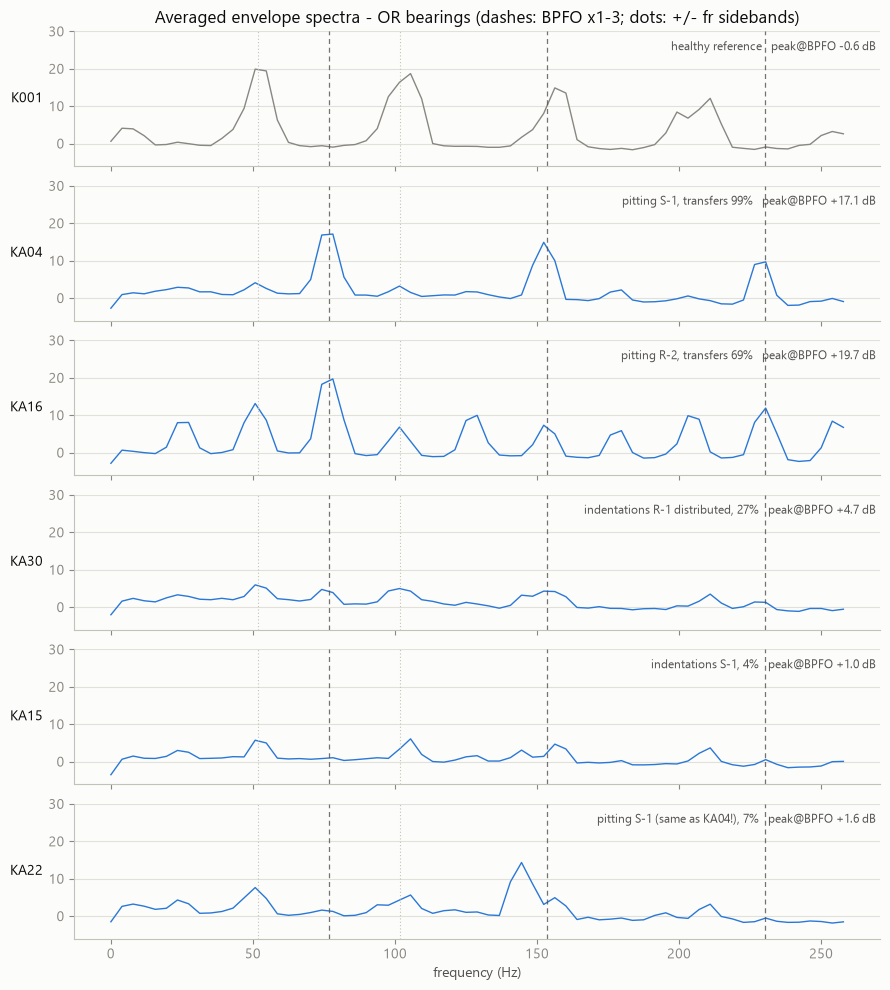

In [3]:
# Averaged envelope spectra, outer-ring story: reference bearings vs the invisible ones
def spectrum_panel(codes, fault="OR", fmax=260):
    fig, axes = plt.subplots(len(codes), 1, figsize=(9, 1.5 * len(codes) + 1),
                             sharex=True, sharey=True)
    for ax, (code_, label, color) in zip(axes, codes):
        spec, fr = avg_env_spectrum(code_)
        bpfo, bpfi = fault_freqs(fr)
        target = bpfo if fault == "OR" else bpfi
        floor = np.median(spec[FLOOR_MASK])
        db = 10 * np.log10(spec / floor)
        m = WIN_FREQS <= fmax
        ax.plot(WIN_FREQS[m], db[m], color=color, lw=1.0)
        for k in (1, 2, 3):
            ax.axvline(k * target, color=INK2, lw=0.9, ls=(0, (4, 3)), alpha=0.8)
        for s in (target - fr, target + fr):
            ax.axvline(s, color=BASE, lw=0.8, ls=(0, (1, 2)))
        band = (WIN_FREQS >= target - 4) & (WIN_FREQS <= target + 4)
        snr = 10 * np.log10(spec[band].max() / floor)
        ax.set_ylabel(code_, rotation=0, ha="right", va="center", color=INK)
        ax.text(0.995, 0.86, f"{label}   peak@{'BPFO' if fault == 'OR' else 'BPFI'} "
                f"{snr:+.1f} dB", transform=ax.transAxes, ha="right", fontsize=8.5,
                color=INK2)
        ax.grid(axis="x", visible=False)
    axes[0].set_title(f"Averaged envelope spectra - {fault} bearings "
                      f"(dashes: {'BPFO' if fault == 'OR' else 'BPFI'} x1-3; "
                      f"dots: +/- fr sidebands)")
    axes[-1].set_xlabel("frequency (Hz)")
    axes[0].set_ylim(-6, 30)
    plt.tight_layout()
    plt.show()


spectrum_panel([
    ("K001", "healthy reference", MUTED),
    ("KA04", "pitting S-1, transfers 99%", C_BLUE),
    ("KA16", "pitting R-2, transfers 69%", C_BLUE),
    ("KA30", "indentations R-1 distributed, 27%", C_BLUE),
    ("KA15", "indentations S-1, 4%", C_BLUE),
    ("KA22", "pitting S-1 (same as KA04!), 7%", C_BLUE),
], fault="OR")

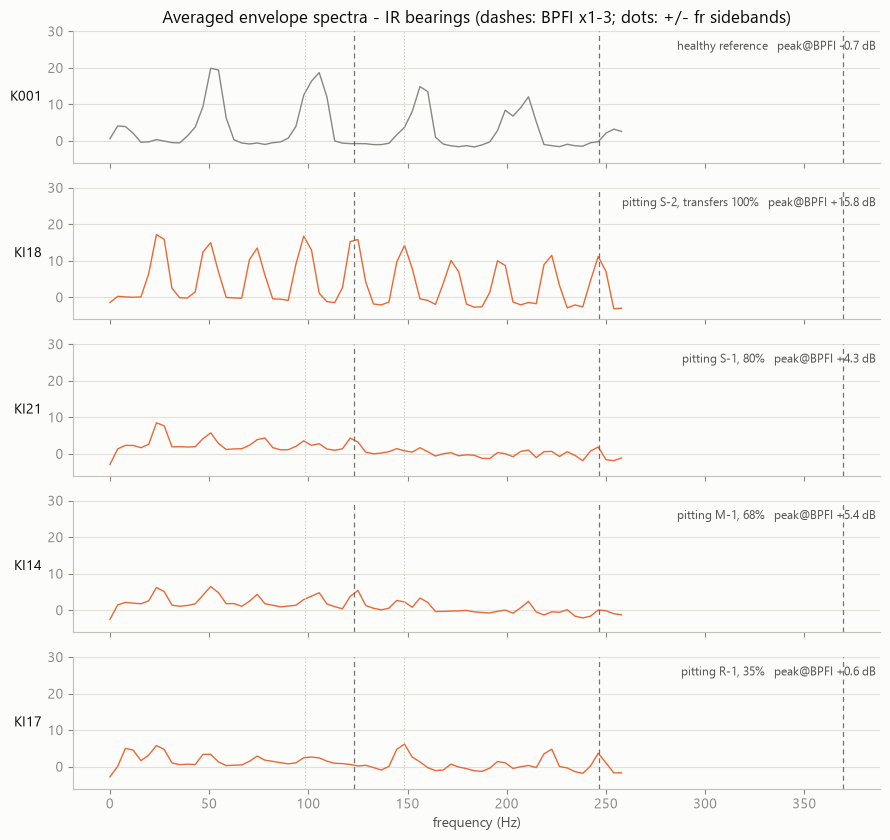

In [4]:
spectrum_panel([
    ("K001", "healthy reference", MUTED),
    ("KI18", "pitting S-2, transfers 100%", C_ORANGE),
    ("KI21", "pitting S-1, 80%", C_ORANGE),
    ("KI14", "pitting M-1, 68%", C_ORANGE),
    ("KI17", "pitting R-1, 35%", C_ORANGE),
], fault="IR")

## Reading the spectra

- **The detected bearings look like the textbook:** KA04 (+17.1 dB) and
  KA16 (+19.7 dB) carry clean BPFO harmonic combs; KI18 a dense BPFI comb
  with shaft-rate sidebands (+15.8 dB).
- **The indentation hypothesis is confirmed:** KA15 (+1.0 dB) and KA30
  (+4.7 dB) are nearly flat at BPFO. The dents roll through smoothly — no
  ball-pass-frequency feature, however thresholded, can detect these two.
- **KA22 is not silent — it rings somewhere else.** Its dominant envelope
  component is **144.5 Hz at +14.3 dB** (where BPFO features read +1.6 dB),
  numerically matching 2×BPFO − FTF (143.9 Hz) ≈ 5.75 fr, and it appears in
  **no other bearing** (K001's peaks are the ≈52.7 Hz rig family at
  105.5/156.2 Hz; KA04's 152.3 Hz is plain 2×BPFO). A feature watching
  144.5 Hz would separate KA22 from healthy perfectly — at this operating
  point. Whether the component is actually fault physics is settled two
  cells down.
- **KI17 is envelope-silent at BPFI (+0.6 dB)** yet learnable per the
  ceiling test — its signature must live outside the envelope comb.

In [5]:
# Best-possible detection: for each problem bearing, train on ALL other 24 bearings
# (6 healthy + 8 artificial + 10 real) - the most favorable training set that
# never contains the test bearing itself.
PROBLEM = ["KA15", "KA22", "KA30", "KI17"]
rows = []
for code_ in PROBLEM:
    train_all_others = dataset[dataset["Code"] != code_]
    sub = TEST[TEST["Code"] == code_]
    row = {"Code": code_}
    for name, feats in (("all-others (12f)", FEATURES_ALL), ("all-others (fund.)", FUND)):
        pred = (RandomForestClassifier(**RF_KW)
                .fit(train_all_others[feats], train_all_others["Condition"])
                .predict(sub[feats]))
        row[name] = (pred == sub["Condition"].iloc[0]).mean()
        if "fund" in name:
            row["-> Healthy (fund.)"] = (pred == "Healthy").mean()
    row["artificial-only (fund.)"] = overview.loc[code_, "Art->Real (fund.)"]
    rows.append(row)
ceiling = pd.DataFrame(rows).set_index("Code")
ceiling = ceiling[["artificial-only (fund.)", "all-others (12f)", "all-others (fund.)",
                   "-> Healthy (fund.)"]]
print(ceiling.to_string(formatters={c: "{:.1%}".format for c in ceiling.columns}))

     artificial-only (fund.) all-others (12f) all-others (fund.) -> Healthy (fund.)
Code                                                                               
KA15                    4.3%             0.3%              12.0%              47.7%
KA22                    6.7%             0.0%              14.7%              38.7%
KA30                   27.0%             8.3%              29.0%              34.7%
KI17                   34.7%            70.7%              43.3%              28.0%


## Reading the ceiling test

- **KA15 (12 %), KA22 (15 %), KA30 (29 %) stay undetected under the most
  favorable training set constructible** — ten real bearings plus all
  artificial and healthy ones. With the current 12 features these three are
  unreachable by *any* training data: for this pipeline they are effectively
  **label noise**, and pooled accuracies that silently average them mislead.
  (The all-12 column is even worse — 0.0–8.3 %, the fingerprint features
  again.)
- **KI17 flips from 35 % to 70.7 %** once real IR bearings and the full
  feature set are in training: a training-domain + feature-coverage problem,
  not physics — the one case of the four the existing pipeline could
  eventually earn honestly.

## The KA22 peak: fault energy or rig resonance?

The OR spectra show KA22's energy concentrated near **144.5 Hz** — not at
BPFO (76.7 Hz) or 2×BPFO (153.5 Hz), but consistent with
**2×BPFO − FTF ≈ 143.9 Hz** (a cage-frequency-displaced outer-race comb
line; equivalently ≈ 5.75 × fr). Two readings are possible: displaced fault
energy, or a structural resonance that has nothing to do with the bearing.
The dataset settles it — the same bearing was recorded at 900 rpm
(`N09_M07_F10`, fr ≈ 15 Hz). **If the component tracks shaft speed it is
fault-related (must move to ≈ 86 Hz); if it stays near 144 Hz it is a fixed
resonance.**

In [6]:
def avg_env_spectrum_cond(code, condition):
    specs, frs = [], []
    for run in range(1, 21):
        chans = load_channels(DATA_DIR / code / f"{condition}_{code}_{run}.mat")
        vib = chans["vibration_1"][:N_KEEP].astype(np.float32)
        frs.append(chans["speed"].mean() / 60.0)
        w = envelope(vib)[: N_WIN * WIN].reshape(N_WIN, WIN)
        w = w - w.mean(axis=1, keepdims=True)
        specs.append((np.abs(np.fft.rfft(w * HANN, axis=1)) ** 2).mean(axis=0))
    return np.mean(specs, axis=0), np.mean(frs)


for cond in ("N15_M07_F10", "N09_M07_F10"):
    spec, fr = avg_env_spectrum_cond("KA22", cond)
    floor = np.median(spec[FLOOR_MASK])
    db = 10 * np.log10(spec / floor)
    bpfo, _ = fault_freqs(fr)
    ftf = fr / 2 * (1 - BALL_D_MM / PITCH_D_MM)
    pred = 2 * bpfo - ftf
    pb = (WIN_FREQS >= pred - 4) & (WIN_FREQS <= pred + 4)
    m = (WIN_FREQS >= 60) & (WIN_FREQS <= 200)
    order = np.argsort(db[m])[::-1][:3]
    tops = ", ".join(f"{WIN_FREQS[m][j]:.1f} Hz ({db[m][j]:+.1f} dB)"
                     for j in sorted(order, key=lambda j: -db[m][j]))
    print(f"{cond}: fr={fr:5.2f}  predicted 2xBPFO-FTF={pred:6.1f} Hz  "
          f"SNR there {10 * np.log10(spec[pb].max() / floor):+5.1f} dB")
    print(f"   top 60-200 Hz peaks: {tops}")

N15_M07_F10: fr=24.99  predicted 2xBPFO-FTF= 143.9 Hz  SNR there +14.3 dB
   top 60-200 Hz peaks: 144.5 Hz (+14.3 dB), 140.6 Hz (+9.2 dB), 148.4 Hz (+8.6 dB)


N09_M07_F10: fr=14.99  predicted 2xBPFO-FTF=  86.3 Hz  SNR there  +2.1 dB
   top 60-200 Hz peaks: 105.5 Hz (+16.1 dB), 156.2 Hz (+14.1 dB), 101.6 Hz (+12.0 dB)


## Verdict: it does not track speed

At 900 rpm the component is simply **gone** — +2.1 dB at the predicted
86.3 Hz, no surviving peak near 144 Hz, and the spectrum is dominated by the
same ≈52.7 Hz rig family the healthy bearing shows. Two consequences:

- The 144.5 Hz line **fails the fault-frequency test**: genuine ball-pass
  energy must scale with shaft speed. It may be a structural/mounting
  resonance excited only under the 1500-rpm condition — possibly *by* the
  fault, but that cannot be claimed from this data.
- Practically, KA22 *is* separable from healthy at `N15_M07_F10` — but only
  in an **anomaly-detection framing** ("this spectrum deviates from the
  healthy baseline"), not by a physics-labeled fault frequency. A fault-comb
  classifier will keep missing it, and an explanation layer that attributed
  a detection to "elevated BPFO" would be **wrong**. For the framework's
  explainability story this is a load-bearing distinction:
  **detectable ≠ attributable.**

## Findings (executed 2026-08-13)

1. **The four invisible bearings have three distinct root causes.**
   *(a) Damage physics* — KA15 and KA30, the set's only plastic-deformation
   (indentation) bearings, produce ≤ +4.7 dB at BPFO: smooth dents do not
   ring, and no ball-pass feature can ever see them.
   *(b) Off-frequency energy* — KA22 carries +14.3 dB at 144.5 Hz but
   +1.6 dB at BPFO; the component does not track shaft speed, so it is
   anomaly-detectable but not fault-attributable.
   *(c) Training domain + feature coverage* — KI17 goes 34.7 % → 70.7 %
   when real IR bearings and all 12 features are available.
2. **Extent level (1–3) does not predict detectability; damage mode and
   spectral structure do.** Metadata alone would have mispredicted KA22
   (profile identical to the 99 %-detected KA04).
3. **Ceiling formalized: with the current 12 features, 3 of 11 real bearings
   are undetectable under any training mix.** Per-bearing reporting is
   mandatory on this benchmark; a pooled mean quietly averages over
   physically impossible cases.
4. **"Real vs artificial" is a difference in kind, not only severity.**
   Real damage introduces new damage *modes* (indentation) and non-textbook
   spectral structure. An impulse-train-at-fault-frequency simulator
   reproduces artificial pitting, not reality. Twin spec: simulate
   damage-mode diversity (pitting *and* indentation contact geometry) or
   scope claims explicitly to pitting-type faults — and pair the
   fault-frequency classifier with a **healthy-baseline anomaly detector**
   for KA22-type cases.
5. Housekeeping: the benchmark's founding paper is archived at
   `literature/10-paderborn-benchmark-lessmeier2016.pdf`; its Table 5 is
   encoded in this notebook.